## Crank-nicolson method for example 1

In [28]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.interpolate import CubicSpline

### 2. Define the Computational Grid

We now define the spatial and time domains for the numerical solution.

The spatial domain is

$$
x \in [-1,1],
$$

and the final time is

$$
T=1.
$$

We divide the spatial domain into \(N_x=20\) intervals and the time interval into \(N_t=100\) time steps. The corresponding spatial and temporal step sizes are

$$
\Delta x = \frac{b-a}{N_x},
\qquad
\Delta t = \frac{T}{N_t}.
$$

The grid points are then generated using `numpy`.


In [2]:
a = -1
b = 1
T = 1

Nx = 20
Nt = 100

dx = (b - a) / Nx
dt = T / Nt

x = np.linspace(a, b, Nx + 1)
t = np.linspace(0, T, Nt + 1)


### 3. Define the Reaction Term

The reaction term in Example 1 is

$$
f(u)=c_su(1-u)(u-a).
$$

For this problem,

$$
c_s=50,\qquad a=0.5.
$$

We define this term as a Python function so that it can be evaluated at the numerical solution during each time step.


In [3]:
# Reaction term for Example 1

def reaction(u, c_s, a):
    return c_s * u * (1 - u) * (u - a)

print("Reaction term defined.")


Reaction term defined.


### 4. Set the Parameters for Example 1

For Example 1, the parameters are

$$
c_d=1,\qquad c_s=50,\qquad a=0.5,
$$

with spatial domain

$$
-1\leq x\leq 1
$$

and final time

$$
T=0.5.
$$

We use `x_left` and `x_right` for the spatial boundaries so that `a` can be used for the reaction parameter.


In [4]:
# Parameters for Example 1

x_left = -1
x_right = 1

T = 0.5

Nx = 20
Nt = 100

c_d = 1
c_s = 50
a = 0.5

dx = (x_right - x_left) / Nx
dt = T / Nt

x = np.linspace(x_left, x_right, Nx + 1)
t = np.linspace(0, T, Nt + 1)

print("Parameters set.")
print("dx =", dx)
print("dt =", dt)

Parameters set.
dx = 0.1
dt = 0.005


In [5]:
# Crank-Nicolson coefficient

r = c_d * dt / (2 * dx**2)

print("r =", r)


r = 0.24999999999999994




### Crank–Nicolson Discretisation

For the diffusion term, the Crank–Nicolson method uses the average of the spatial second derivative at time levels \(n\) and \(n+1\), while the reaction term is treated explicitly at time level \(n\):

$$
\frac{u_i^{n+1}-u_i^n}{\Delta t}
=
\frac{c_d}{2}
\left[
\frac{u_{i+1}^{n+1}-2u_i^{n+1}+u_{i-1}^{n+1}}{\Delta x^2}
+
\frac{u_{i+1}^{n}-2u_i^{n}+u_{i-1}^{n}}{\Delta x^2}
\right]
+
c_su_i^n(1-u_i^n)(u_i^n-a).
$$

Defining

$$
r=\frac{c_d\Delta t}{2\Delta x^2},
$$

and rearranging gives

$$
-r u_{i-1}^{n+1}
+(1+2r)u_i^{n+1}
-r u_{i+1}^{n+1}
=
r u_{i-1}^{n}
+(1-2r)u_i^{n}
+r u_{i+1}^{n}
+\Delta t\,c_su_i^n(1-u_i^n)(u_i^n-a).
$$

Therefore, for the interior points, the left-hand side can be written as

$$
A\mathbf{u}^{n+1}=\mathbf{b}^n,
$$

where

$$
A=
\begin{pmatrix}
1+2r & -r & 0 & \cdots & 0\\
-r & 1+2r & -r & \ddots & \vdots\\
0 & -r & 1+2r & \ddots & 0\\
\vdots & \ddots & \ddots & \ddots & -r\\
0 & \cdots & 0 & -r & 1+2r
\end{pmatrix}.
$$


In [6]:
# Crank-Nicolson matrix A

N = Nx - 1  # number of interior points

A = np.zeros((N, N))

for i in range(N):
    A[i, i] = 1 + 2*r

    if i > 0:
        A[i, i-1] = -r

    if i < N - 1:
        A[i, i+1] = -r

print("Matrix A:")
print(A)


Matrix A:
[[ 1.5  -0.25  0.    0.    0.    0.    0.    0.    0.    0.    0.    0.
   0.    0.    0.    0.    0.    0.    0.  ]
 [-0.25  1.5  -0.25  0.    0.    0.    0.    0.    0.    0.    0.    0.
   0.    0.    0.    0.    0.    0.    0.  ]
 [ 0.   -0.25  1.5  -0.25  0.    0.    0.    0.    0.    0.    0.    0.
   0.    0.    0.    0.    0.    0.    0.  ]
 [ 0.    0.   -0.25  1.5  -0.25  0.    0.    0.    0.    0.    0.    0.
   0.    0.    0.    0.    0.    0.    0.  ]
 [ 0.    0.    0.   -0.25  1.5  -0.25  0.    0.    0.    0.    0.    0.
   0.    0.    0.    0.    0.    0.    0.  ]
 [ 0.    0.    0.    0.   -0.25  1.5  -0.25  0.    0.    0.    0.    0.
   0.    0.    0.    0.    0.    0.    0.  ]
 [ 0.    0.    0.    0.    0.   -0.25  1.5  -0.25  0.    0.    0.    0.
   0.    0.    0.    0.    0.    0.    0.  ]
 [ 0.    0.    0.    0.    0.    0.   -0.25  1.5  -0.25  0.    0.    0.
   0.    0.    0.    0.    0.    0.    0.  ]
 [ 0.    0.    0.    0.    0.    0.    0.   -0.25  1.5

In [29]:
# Crank-Nicolson matrix B

B = np.zeros((N, N))

for i in range(N):
    B[i, i] = 1 - 2*r

    if i > 0:
        B[i, i-1] = r

    if i < N - 1:
        B[i, i+1] = r

print("Matrix B:")
print(B)


Matrix B:
[[0.5  0.25 0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
  0.   0.   0.   0.   0.  ]
 [0.25 0.5  0.25 0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
  0.   0.   0.   0.   0.  ]
 [0.   0.25 0.5  0.25 0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
  0.   0.   0.   0.   0.  ]
 [0.   0.   0.25 0.5  0.25 0.   0.   0.   0.   0.   0.   0.   0.   0.
  0.   0.   0.   0.   0.  ]
 [0.   0.   0.   0.25 0.5  0.25 0.   0.   0.   0.   0.   0.   0.   0.
  0.   0.   0.   0.   0.  ]
 [0.   0.   0.   0.   0.25 0.5  0.25 0.   0.   0.   0.   0.   0.   0.
  0.   0.   0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.25 0.5  0.25 0.   0.   0.   0.   0.   0.
  0.   0.   0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.   0.25 0.5  0.25 0.   0.   0.   0.   0.
  0.   0.   0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.   0.   0.25 0.5  0.25 0.   0.   0.   0.
  0.   0.   0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.   0.   0.   0.25 0.5  0.25 0.   0.   0.
  0.   0.   0.   0.   0.  ]
 [0.   0. 

### Initial Condition

The initial condition for Example 1 is

$$
u(x,0)=e^{-x^2}, \qquad -1\leq x\leq1.
$$

At the grid points \(x_i\), the initial numerical solution is therefore

$$
u_i^0=e^{-x_i^2}.
$$


In [30]:
# Initial condition

u = np.exp(-x**2)

print("Initial condition:")
print(u)


Initial condition:
[0.36787944 0.44485807 0.52729242 0.61262639 0.69767633 0.77880078
 0.85214379 0.91393119 0.96078944 0.99004983 1.         0.99004983
 0.96078944 0.91393119 0.85214379 0.77880078 0.69767633 0.61262639
 0.52729242 0.44485807 0.36787944]


In [31]:
# Boundary conditions

boundary_value = np.exp(-1)

u[0] = boundary_value
u[-1] = boundary_value

print("Boundary value =", boundary_value)

Boundary value = 0.36787944117144233


In [32]:
# Reaction contribution

reaction_term = dt * reaction(u[1:-1], c_s, a)

print("Reaction contribution:")
print(reaction_term)

Reaction contribution:
[-0.00340445  0.00170069  0.00668199  0.01042367  0.01200726  0.01109207
  0.00814006  0.00433984  0.00120689  0.          0.00120689  0.00433984
  0.00814006  0.01109207  0.01200726  0.01042367  0.00668199  0.00170069
 -0.00340445]


In [33]:
# Boundary contribution to the right-hand side

boundary_contribution = np.zeros(N)

boundary_contribution[0] = r * u[0] + r * u[0]
boundary_contribution[-1] = r * u[-1] + r * u[-1]

print("Boundary contribution:")
print(boundary_contribution)


Boundary contribution:
[0.18393972 0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.18393972]


In [34]:
# Construct the right-hand side vector

rhs = B @ u[1:-1] + reaction_term + boundary_contribution

print("Right-hand side:")
print(rhs)

Right-hand side:
[0.53478741 0.52971802 0.61923738 0.70711863 0.78886268 0.86034695
 0.91833896 0.96072982 0.98642917 0.99502492 0.98642917 0.96072982
 0.91833896 0.86034695 0.78886268 0.70711863 0.61923738 0.52971802
 0.53478741]


In [35]:
# Solve for the next time step

u_new_interior = np.linalg.solve(A, rhs)

print("Interior solution at next time step:")
print(u_new_interior)


Interior solution at next time step:
[0.44493151 0.53043945 0.61883309 0.7056096  0.78634997 0.85703948
 0.91449907 0.95659911 0.9821763  0.99074205 0.9821763  0.95659911
 0.91449907 0.85703948 0.78634997 0.7056096  0.61883309 0.53043945
 0.44493151]


In [36]:
# Construct the full solution at the next time step

u_new = np.zeros(Nx + 1)

u_new[0] = boundary_value
u_new[-1] = boundary_value
u_new[1:-1] = u_new_interior

print("Full solution at t =", dt)
print(u_new)


Full solution at t = 0.005
[0.36787944 0.44493151 0.53043945 0.61883309 0.7056096  0.78634997
 0.85703948 0.91449907 0.95659911 0.9821763  0.99074205 0.9821763
 0.95659911 0.91449907 0.85703948 0.78634997 0.7056096  0.61883309
 0.53043945 0.44493151 0.36787944]


In [37]:
# Update the solution for the next time step

u = u_new.copy()




In [20]:
# Reset to the true initial condition

u = np.exp(-x**2)
u[0] = boundary_value
u[-1] = boundary_value

U_CN = np.zeros((Nt + 1, Nx + 1))
U_CN[0, :] = u

for n in range(Nt):

    reaction_term = dt * reaction(u[1:-1], c_s, a)

    boundary_contribution = np.zeros(N)
    boundary_contribution[0] = 2 * r * boundary_value
    boundary_contribution[-1] = 2 * r * boundary_value

    rhs = B @ u[1:-1] + reaction_term + boundary_contribution

    u_new_interior = np.linalg.solve(A, rhs)

    u_new = np.zeros(Nx + 1)
    u_new[0] = boundary_value
    u_new[-1] = boundary_value
    u_new[1:-1] = u_new_interior

    u = u_new.copy()
    U_CN[n + 1, :] = u



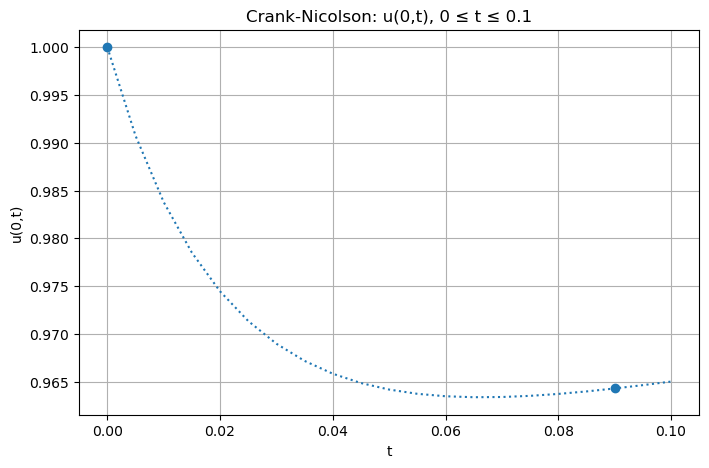

In [38]:
# Plot u(0,t) for 0 <= t <= 0.1

x0_index = np.argmin(np.abs(x - 0))
mask = t <= 0.1

plt.figure(figsize=(8, 5))

plt.plot(t[mask], U_CN[mask, x0_index], marker ="o",markevery=18, linestyle=':')

plt.xlabel("t")
plt.ylabel("u(0,t)")
plt.title("Crank-Nicolson: u(0,t), 0 ≤ t ≤ 0.1")
plt.grid()

plt.show()

##  Using Mathematica NDSolve as Reference Solution

In [39]:


# --------------------------------------------
# Load Mathematica NDSolve reference at t = 0.5
# --------------------------------------------

ndsolve_data = pd.read_csv(
    "mathematica_ndsolve_t05.csv"
)

x_nd = ndsolve_data["x"].to_numpy(dtype=float)
u_nd = ndsolve_data["u"].to_numpy(dtype=float)

# Make sure points are ordered from -1 to 1
sort_idx = np.argsort(x_nd)

x_nd = x_nd[sort_idx]
u_nd = u_nd[sort_idx]

# Interpolating function for Mathematica reference
ndsolve_interp = CubicSpline(
    x_nd,
    u_nd
)

print("NDSolve reference loaded successfully.")
print("Number of reference points =", len(x_nd))
print("x-range =", (x_nd[0], x_nd[-1]))
print("Boundary values =", (u_nd[0], u_nd[-1]))

NDSolve reference loaded successfully.
Number of reference points = 2001
x-range = (np.float64(-1.0), np.float64(1.0))
Boundary values = (np.float64(0.3678794411714423), np.float64(0.3678794411714423))


In [ ]:
# # Fine grid for the reference solution

# Nx_ref = 200
# Nt_ref = 1000

# dx_ref = (x_right - x_left) / Nx_ref
# dt_ref = T / Nt_ref

# x_ref = np.linspace(x_left, x_right, Nx_ref + 1)
# t_ref = np.linspace(0, T, Nt_ref + 1)

# print("dx_ref =", dx_ref)
# print("dt_ref =", dt_ref)

dx_ref = 0.01
dt_ref = 0.0005


In [ ]:
# Reference solution using Crank-Nicolson

# N_ref = Nx_ref - 1

# r_ref = c_d * dt_ref / (2 * dx_ref**2)

# A_ref = np.zeros((N_ref, N_ref))
# B_ref = np.zeros((N_ref, N_ref))

# for i in range(N_ref):
#     A_ref[i, i] = 1 + 2*r_ref
#     B_ref[i, i] = 1 - 2*r_ref

#     if i > 0:
#         A_ref[i, i-1] = -r_ref
#         B_ref[i, i-1] = r_ref

#     if i < N_ref - 1:
#         A_ref[i, i+1] = -r_ref
#         B_ref[i, i+1] = r_ref

# u_ref = np.exp(-x_ref**2)

# boundary_value_ref = np.exp(-1)

# u_ref[0] = boundary_value_ref
# u_ref[-1] = boundary_value_ref

# U_ref = np.zeros((Nt_ref + 1, Nx_ref + 1))
# U_ref[0, :] = u_ref

# for n in range(Nt_ref):

#     reaction_term_ref = dt_ref * reaction(u_ref[1:-1], c_s, a)

#     boundary_contribution_ref = np.zeros(N_ref)
#     boundary_contribution_ref[0] = 2 * r_ref * boundary_value_ref
#     boundary_contribution_ref[-1] = 2 * r_ref * boundary_value_ref

#     rhs_ref = B_ref @ u_ref[1:-1] + reaction_term_ref + boundary_contribution_ref

#     u_new_interior_ref = np.linalg.solve(A_ref, rhs_ref)

#     u_new_ref = np.zeros(Nx_ref + 1)
#     u_new_ref[0] = boundary_value_ref
#     u_new_ref[-1] = boundary_value_ref
#     u_new_ref[1:-1] = u_new_interior_ref

#     u_ref = u_new_ref.copy()
#     U_ref[n + 1, :] = u_ref



In [ ]:
# Maximum absolute error of the Crank-Nicolson solution

# U_ref_coarse = U_ref[::10, ::10]

# absolute_error = np.abs(U_CN - U_ref_coarse)

# max_absolute_error = np.max(absolute_error)

# print("Maximum absolute error =", max_absolute_error)


Maximum absolute error = 0.002800615260332817


In [44]:
# Grid sizes for the maximum error analysis

Nx_values = [5, 10, 15, 20, 25, 30]

max_errors = []

print("Grid sizes:", Nx_values)


Grid sizes: [5, 10, 15, 20, 25, 30]


In [45]:
# Calculate maximum absolute error for each grid size

max_errors = []

for Nx_test in Nx_values:

    Nt_test = int(500 * Nx_test)

    dx_test = (x_right - x_left) / Nx_test
    dt_test = T / Nt_test

    x_test = np.linspace(x_left, x_right, Nx_test + 1)

    N_test = Nx_test - 1
    r_test = c_d * dt_test / (2 * dx_test**2)

    A_test = np.zeros((N_test, N_test))
    B_test = np.zeros((N_test, N_test))

    for i in range(N_test):
        A_test[i, i] = 1 + 2*r_test
        B_test[i, i] = 1 - 2*r_test

        if i > 0:
            A_test[i, i-1] = -r_test
            B_test[i, i-1] = r_test

        if i < N_test - 1:
            A_test[i, i+1] = -r_test
            B_test[i, i+1] = r_test

    u_test = np.exp(-x_test**2)
    u_test[0] = boundary_value
    u_test[-1] = boundary_value

    for n in range(Nt_test):

        reaction_term_test = dt_test * reaction(u_test[1:-1], c_s, a)

        boundary_contribution_test = np.zeros(N_test)
        boundary_contribution_test[0] = 2 * r_test * boundary_value
        boundary_contribution_test[-1] = 2 * r_test * boundary_value

        rhs_test = (
            B_test @ u_test[1:-1]
            + reaction_term_test
            + boundary_contribution_test
        )

        u_new_interior_test = np.linalg.solve(A_test, rhs_test)

        u_new_test = np.zeros(Nx_test + 1)
        u_new_test[0] = boundary_value
        u_new_test[-1] = boundary_value
        u_new_test[1:-1] = u_new_interior_test

        u_test = u_new_test

    # Mathematica NDSolve solution evaluated  at exactly the CN grid points

    u_nd_at_cn = ndsolve_interp(x_test)

    # Maximum absolute error at t = 0.5
    error = np.abs( u_test - u_nd_at_cn)

    max_error = np.max(error)

    max_errors.append(max_error)

    print("Nx =", Nx_test, "Maximum error =", max_error)

Nx = 5 Maximum error = 0.03781606636218959
Nx = 10 Maximum error = 0.01115177659189659
Nx = 15 Maximum error = 0.00515250861467087
Nx = 20 Maximum error = 0.0028971426845944004
Nx = 25 Maximum error = 0.001846061717789227
Nx = 30 Maximum error = 0.0012899068166161154


In [47]:
Nx_values = np.array(Nx_values)
max_errors = np.array(max_errors)

### Convergence Analysis

we need to  determine the convergence of the Crank–Nicolson method, we compare the maximum absolute error obtained using different spatial grid sizes.



In [48]:
dx_values = (x_right - x_left) / Nx_values

convergence_orders = []

for i in range(1, len(Nx_values)):
    p = np.log(max_errors[i-1] / max_errors[i]) / np.log(dx_values[i-1] / dx_values[i])
    convergence_orders.append(p)

print("Convergence orders:")
for i, p in enumerate(convergence_orders, start=1):
    print(f"{Nx_values[i-1]} -> {Nx_values[i]}: p = {p:.4f}")

Convergence orders:
5 -> 10: p = 1.7617
10 -> 15: p = 1.9043
15 -> 20: p = 2.0014
20 -> 25: p = 2.0196
25 -> 30: p = 1.9662


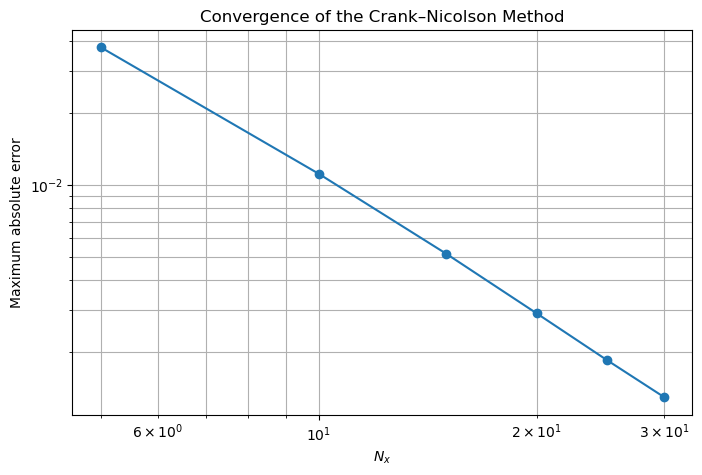

In [49]:
plt.figure(figsize=(8, 5))

plt.loglog(Nx_values, max_errors, 'o-')

plt.xlabel("$N_x$")
plt.ylabel("Maximum absolute error")
plt.title("Convergence of the Crank–Nicolson Method")
plt.grid(True, which="both")

plt.show()

### Discussion of Crank--Nicolson Results

The Crank--Nicolson method was applied to Example 1 and the numerical
solution was compared with a reference solution generated using
Mathematica's `NDSolve`.

For each spatial resolution, the numerical solution was evaluated at

$$
t=0.5,
$$

and the maximum absolute error was calculated as

$$
E_{\max}
=
\max_i
\left|
u_{\mathrm{CN}}(x_i,0.5)
-
u_{\mathrm{NDSolve}}(x_i,0.5)
\right|.
$$

The following results were obtained:

| $N_x$ | Maximum Absolute Error | Observed Convergence Order |
|---:|---:|---:|
| 5  | 0.0378161 | --- |
| 10 | 0.0111518 | 1.7617 |
| 15 | 0.0051525 | 1.9043 |
| 20 | 0.0028971 | 2.0014 |
| 25 | 0.0018461 | 2.0196 |
| 30 | 0.0012899 | 1.9662 |

The maximum absolute error decreases consistently as the spatial grid is
refined. At the coarsest resolution,

$$
N_x=5,
$$

the error is approximately

$$
0.0378161,
$$

whereas at

$$
N_x=30,
$$

the error has decreased to approximately

$$
0.0012899.
$$

This monotonic decrease indicates that the numerical solution approaches
the Mathematica `NDSolve` reference solution as the grid is refined.

The observed convergence orders also become increasingly close to

$$
p=2.
$$

In particular, the convergence orders for the finer grids are

$$
2.0014,\qquad
2.0196,\qquad
1.9662.
$$

This shows approximately second-order convergence with respect to the
grid refinement used in this experiment. The behaviour is consistent
with the second-order central finite-difference approximation used for
the spatial second derivative.

The result at $N_x=5$ gives a lower observed order of approximately

$$
p=1.7617,
$$

which is less representative of the asymptotic convergence behaviour
because the grid is still relatively coarse. As the grid is refined,
the observed order approaches $2$ more clearly.

### Comparison with the Original Paper

The original article also evaluates Example 1 at

$$
t=0.5
$$

by comparing its numerical solution with Mathematica's `NDSolve`
solution for $\alpha=1$.

The errors reported in the article are:

| $N_x$ | Error reported in the original article |
|---:|---:|
| 5  | 0.0291456 |
| 10 | 0.0001561 |
| 15 | 0.0001499 |
| 20 | 0.0001495 |
| 25 | 0.0001495 |
| 30 | 0.0001495 |

At the lowest resolution, the two methods give errors of the same order
of magnitude. For example,

$$
E_{\mathrm{CN}}(N_x=5)
\approx
0.0378161,
$$

while the article reports approximately

$$
0.0291456.
$$

However, a noticeable difference becomes visible as the spatial
resolution is increased.

For example, at

$$
N_x=10,
$$

the Crank--Nicolson calculation gives

$$
E_{\mathrm{CN}}
\approx
0.0111518,
$$

whereas the method used in the original article gives approximately

$$
0.0001561.
$$

The Crank--Nicolson error continues to decrease steadily as $N_x$
increases, while the errors reported in the article decrease rapidly
between $N_x=5$ and $N_x=10$ and then remain approximately constant near

$$
0.0001495.
$$

The difference in behaviour is expected because the two approaches use
different numerical discretizations. The present calculation uses a
finite-difference-based Crank--Nicolson approach, whereas the original
article uses quasilinearization, Chebyshev collocation in space and a
Laplace-transform-based treatment of time.

Although both calculations use Mathematica `NDSolve` as the numerical
reference, the error values should not be expected to agree exactly
because the numerical methods are different. In addition, the parameter
values used in the present study were adopted as working values and are
not explicitly stated in the original article.

Overall, the Crank--Nicolson results demonstrate systematic convergence
towards the `NDSolve` reference solution. The observed convergence order
is approximately $2$ for the finer grids, while the maximum absolute
error decreases from 0.0378161 at $N_x=5$ to 0.0012899 at $N_x=30$.